# 5.Clasificación ideológica de noticias en español
## Análisis del Ground truth

Este notebook es el **quinto paso del pipeline**, que tiene como objetivo analizar el ground truth y hacer el preprocesado para generar los modelos del clasificación ideológica

In [1]:
import warnings
warnings.filterwarnings('ignore')

import json
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from IPython.display import display, clear_output
from pathlib import Path
from scipy.stats import chi2_contingency
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from statsmodels.stats.inter_rater import fleiss_kappa, aggregate_raters


## Sección 1: Análisis del Ground Truth

### 0. Setup y configuración global

In [2]:
# Estilo global
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.15)
plt.rcParams.update({'figure.dpi': 130, 'axes.titlesize': 13, 'axes.labelsize': 11})

PALETTE      = {'IZQUIERDA': '#2166ac', 'CENTRO': '#969696', 'DERECHA': '#d6604d'}
PAL_ACCION   = {'INCLUIR': '#4dac26',   'REVISAR': '#f1a340', 'DESCARTAR': '#d01c8b'}
LABELS_ORDEN = ['IZQUIERDA', 'CENTRO', 'DERECHA']

STOPWORDS_ES = [
    'de','la','el','en','y','a','los','del','se','las','por','un','para','con',
    'no','una','su','al','lo','como','más','pero','sus','le','ya','o','este',
    'sí','porque','esta','entre','cuando','muy','sin','sobre','ser','tiene',
    'también','me','hasta','hay','donde','han','quien','están','estado','antes',
    'qué','esto','fue','ha','si','te','que','es','son','era','sido','ser','estar',
    'algo','todo','cada','tan','bien','vez','así','aunque','sino','tras','ante',
    'bajo','caso','año','años','según','mismo','misma','parte','puede','solo',
]

# Rutas
ROOT    = Path('..')
GT_DIR  = ROOT / 'data' / 'ground_truth'
OUT_DIR = GT_DIR

np.random.seed(42)
print('Setup OK')


Setup OK


### 1.1 Cargar dataset y verificación de integridad

In [5]:
gt  = pd.read_parquet(GT_DIR / 'ground_truth_results.parquet')
art = pd.read_csv(GT_DIR / 'articulos_3000.csv')[['id', 'noticia', 'abstract']]
df  = gt.merge(art, on='id', how='left')

df['texto'] = (
    df['titular'].fillna('') + ' ' +
    df['noticia'].fillna('').apply(lambda x: ' '.join(str(x).split()[:400]))
).str.strip()

mbfc_order = (df.drop_duplicates('medio')[['medio', 'mbfc_score']]
                .sort_values('mbfc_score')['medio'].tolist())

print(f'Artículos cargados : {len(df):,}')
print(f'Columnas           : {len(df.columns)}')
print(f'Medios (izq → der) : {mbfc_order}')

print('\nNulos en columnas clave ')
cols_clave = ['claude_label', 'gpt_label', 'llama_label',
              'final_label', 'accion', 'confianza_voto']
for col in cols_clave:
    n_null = df[col].isna().sum()
    print(f'  {col:<22}: {"0 nulos" if n_null == 0 else f"{n_null} nulos"}')

print(f'\nErrores LLM')
for llm in ['claude', 'gpt', 'llama']:
    n_err = df[f'{llm}_error'].notna().sum()
    print(f'  {llm}_error: {"0" if n_err == 0 else f"{n_err}"}')


# Excluir artículos INCLUIR que no superaron el filtro del notebook
_valid_ids = set()
for _m in ['elconfidencial','eldiario','publico','okdiario','elpais','elmundo']:
    with open(ROOT / 'data' / 'processed' / f'{_m}_limpio_filtrado.json') as _f:
        _valid_ids.update(a['id'] for a in json.load(_f))
_n_before = len(df)
df = df[df['id'].isin(_valid_ids) | (df['accion'] != 'INCLUIR')].reset_index(drop=True)
print(f'Excluidos (INCLUIR sin corpus filtrado): {_n_before - len(df)} artículos')
print(f'df final: {len(df):,} artículos  ')

Artículos cargados : 3,000
Columnas           : 40
Medios (izq → der) : ['Público', 'elDiario.es', 'El País', 'El Confidencial', 'El Mundo', 'OKDiario']

Nulos en columnas clave 
  claude_label          : 0 nulos
  gpt_label             : 0 nulos
  llama_label           : 0 nulos
  final_label           : 90 nulos
  accion                : 0 nulos
  confianza_voto        : 0 nulos

Errores LLM
  claude_error: 0
  gpt_error: 0
  llama_error: 0
Excluidos (INCLUIR sin corpus filtrado): 7 artículos
df final: 2,993 artículos  


### 1.2 Estadísticas básicas + patrones de votación LLM

ESTADÍSTICAS BÁSICAS  (pre-revisión manual)

Total artículos: 2,993

Por acción:
  INCLUIR     : 2,329  (77.8%)
  REVISAR     :   574  (19.2%)
  DESCARTAR   :    90  (3.0%)

Etiquetas INCLUIR (n=2,329):
  CENTRO      :   942  (40.4%)
  IZQUIERDA   :   819  (35.2%)
  DERECHA     :   568  (24.4%)

Patrones de votación  (Claude/GPT/Llama) — n=2,993:
  Patrón               N  Acción dominante
  ────────────────────────────────────────
  CEN/CEN/CEN        847  (28.3%)  → INCLUIR
  IZQ/IZQ/IZQ        561  (18.7%)  → INCLUIR
  CEN/CEN/IZQ        525  (17.5%)  → REVISAR
  DER/DER/IZQ        304  (10.2%)  → INCLUIR
  DER/DER/DER        147  (4.9%)  → INCLUIR
  IZQ/CEN/IZQ        101  (3.4%)  → INCLUIR
  CEN/CEN/DER         95  (3.2%)  → INCLUIR
  IZQ/IZQ/CEN         64  (2.1%)  → INCLUIR
  DER/CEN/IZQ         51  (1.7%)  → DESCARTAR
  DER/DER/CEN         47  (1.6%)  → INCLUIR
  IZQ/CEN/CEN         43  (1.4%)  → REVISAR
  IZQ/IZQ/DER         42  (1.4%)  → INCLUIR
  CEN/IZQ/IZQ         40  (1.3%

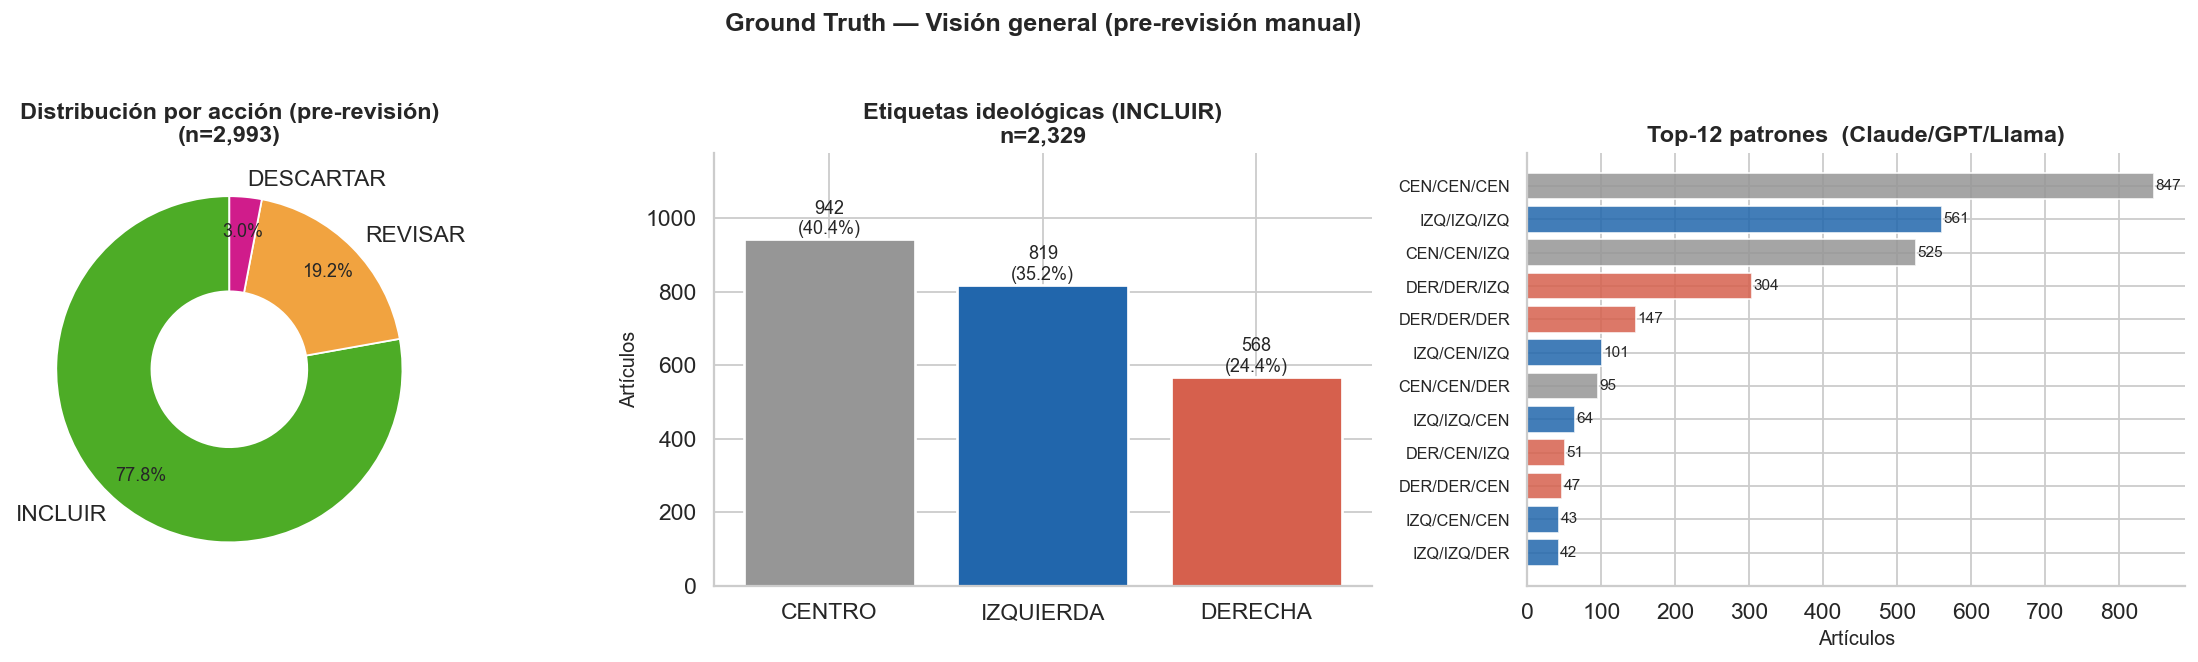

In [6]:
# Reconstruir estado PRE-revisión
df_pre = df.copy()
mask_manual = df_pre['razonamiento_voto'].str.startswith('Revisado manualmente', na=False)
df_pre.loc[mask_manual, 'accion'] = 'REVISAR'

n_total       = len(df_pre)
accion_counts = df_pre['accion'].value_counts()
df_inc        = df_pre[df_pre['accion'] == 'INCLUIR']
label_counts  = df_inc['final_label'].value_counts()

print('=' * 55)
print('ESTADÍSTICAS BÁSICAS  (pre-revisión manual)')
print('=' * 55)
print(f'\nTotal artículos: {n_total:,}')
print(f'\nPor acción:')
for a, n in accion_counts.items():
    print(f'  {a:<12}: {n:>5,}  ({n/n_total*100:.1f}%)')
print(f'\nEtiquetas INCLUIR (n={len(df_inc):,}):')
for l, n in label_counts.items():
    print(f'  {l:<12}: {n:>5,}  ({n/len(df_inc)*100:.1f}%)')

abbr = {'IZQUIERDA': 'IZQ', 'CENTRO': 'CEN', 'DERECHA': 'DER'}
df_v = df_pre[df_pre['claude_label'].isin(LABELS_ORDEN) &
              df_pre['gpt_label'].isin(LABELS_ORDEN) &
              df_pre['llama_label'].isin(LABELS_ORDEN)].copy()
df_v['patron'] = (df_v['claude_label'].map(abbr) + '/' +
                  df_v['gpt_label'].map(abbr) + '/' +
                  df_v['llama_label'].map(abbr))
patron_total = df_v['patron'].value_counts()

print(f'\nPatrones de votación  (Claude/GPT/Llama) — n={len(df_v):,}:')
print(f'  {"Patrón":<16} {"N":>5}  {"Acción dominante"}')
print('  ' + '─' * 40)
for patron, cnt in patron_total.items():
    acc = df_v[df_v['patron'] == patron]['accion'].value_counts().index[0]
    pct = cnt / len(df_v) * 100
    print(f'  {patron:<16} {cnt:>5,}  ({pct:.1f}%)  → {acc}')


fig, axes = plt.subplots(1, 3, figsize=(18, 5))

colors_acc = [PAL_ACCION[a] for a in accion_counts.index]
wedges, texts, autotexts = axes[0].pie(
    accion_counts, labels=accion_counts.index, colors=colors_acc,
    autopct='%1.1f%%', startangle=90, pctdistance=0.80,
    wedgeprops=dict(width=0.55))
for t in autotexts: t.set_fontsize(10)
axes[0].set_title(f'Distribución por acción (pre-revisión)\n(n={n_total:,})', fontweight='bold')

# Bar — etiquetas INCLUIR
colors_lab = [PALETTE[l] for l in label_counts.index]
bars = axes[1].bar(label_counts.index, label_counts.values,
                   color=colors_lab, edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, label_counts.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3,
                 f'{val:,}\n({val/len(df_inc)*100:.1f}%)',
                 ha='center', va='bottom', fontsize=10)
axes[1].set_title(f'Etiquetas ideológicas (INCLUIR)\nn={len(df_inc):,}', fontweight='bold')
axes[1].set_ylabel('Artículos')
axes[1].set_ylim(0, label_counts.max() * 1.25)
sns.despine(ax=axes[1])

# Patrones de votación — top 12
top_p = patron_total.head(12)
col_map = {'IZQ': '#2166ac', 'DER': '#d6604d', 'CEN': '#969696'}
colors_p = [col_map.get(p.split('/')[0], '#888') for p in top_p.index]
axes[2].barh(range(len(top_p)), top_p.values[::-1],
             color=colors_p[::-1], alpha=0.85, edgecolor='white')
axes[2].set_yticks(range(len(top_p)))
axes[2].set_yticklabels(top_p.index[::-1], fontsize=9)
axes[2].set_xlabel('Artículos')
axes[2].set_title('Top-12 patrones  (Claude/GPT/Llama)', fontweight='bold')
for i, val in enumerate(top_p.values[::-1]):
    axes[2].text(val + 2, i, f'{val:,}', va='center', fontsize=8.5)
sns.despine(ax=axes[2])

plt.suptitle('Ground Truth — Visión general (pre-revisión manual)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(OUT_DIR / '1_2_estadisticas_basicas.png', dpi=150, bbox_inches='tight')
plt.show()

Antes de la revisión manual, el sistema de votación resolvió automáticamente ~78% de los artículos como INCLUIR con mayoría clara. El 19% quedó en REVISAR por desacuerdo entre modelos. Los patrones con acuerdo total (IZQ/IZQ/IZQ, DER/DER/DER, CEN/CEN/CEN) dominan, confirmando que la señal ideológica es inequívoca en la mayoría de artículos. Las clases resultantes: **IZQUIERDA 35%**, **CENTRO 40%**, **DERECHA 24%**.

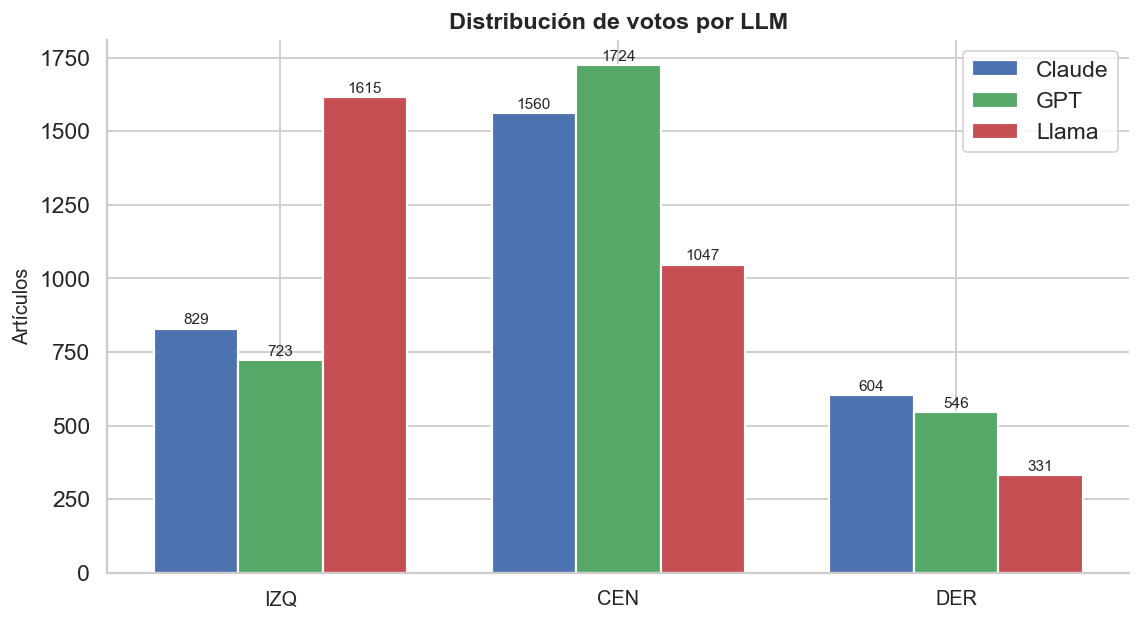

In [5]:
# Distribución de votos por LLM

ORDER  = ["IZQUIERDA", "CENTRO", "DERECHA"]
llm_cols = [("Claude", "claude_label"), ("GPT", "gpt_label"), ("Llama", "llama_label")]
LLM_COLORS = {"Claude": "#4c72b0", "GPT": "#55a868", "Llama": "#c44e52"}

data = {nombre: df[col].value_counts().reindex(ORDER, fill_value=0).values
        for nombre, col in llm_cols}

x   = np.arange(len(ORDER))
w   = 0.25
fig, ax = plt.subplots(figsize=(9, 5))

for i, (nombre, vals) in enumerate(data.items()):
    bars = ax.bar(x + i*w, vals, width=w, label=nombre,
                  color=LLM_COLORS[nombre], edgecolor="white", linewidth=1.2)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                str(val), ha="center", va="bottom", fontsize=8.5)

ax.set_xticks(x + w)
ax.set_xticklabels(["IZQ", "CEN", "DER"], fontsize=11)
ax.set_ylabel("Artículos")
ax.set_title("Distribución de votos por LLM", fontweight="bold")
ax.legend()
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig(OUT_DIR / "1_2b_votos_por_llm.png", dpi=150, bbox_inches="tight")
plt.show()


### 1.3 Revisión interactiva de casos REVISAR

In [6]:
df_rev = df[df["accion"] == "REVISAR"].copy().reset_index()
_state = {"pos": 0, "decisions": {}}
_out   = widgets.Output(layout=widgets.Layout(width="100%", min_height="480px", overflow_y="auto", border="1px solid #ddd", padding="8px"))

def _fmt_lexico(val):
    if not val or str(val) == "nan":
        return "—"
    try:
        lst = json.loads(str(val))
        return ", ".join(lst) if isinstance(lst, list) else str(val)
    except Exception:
        return str(val)

def _fmt(val, maxlen=300, width=88):
    s = str(val) if val and str(val) != "nan" else "—"
    s = s[:maxlen] + "…" if len(s) > maxlen else s
    return textwrap.fill(s, width=width, subsequent_indent="             ")

def _mostrar(pos):
    with _out:
        clear_output(wait=True)
        if pos >= len(df_rev):
            print(f"✓ Revisión completada — {len(_state['decisions'])} decisiones de {len(df_rev):,}")
            return
        row = df_rev.iloc[pos]
        sep = "─" * 65
        print(sep)
        fecha = str(row.get('fecha', ''))[:10]
        tema  = row.get('tema', '')
        print(f"[{pos+1}/{len(df_rev)}]  {row['medio']}  |  {fecha}  |  {tema}")
        print(sep)
        print(f"TITULAR : {row['titular']}")
        print(f"\nVOTO    : {str(row['final_label']):<12}  Confianza: {row['confianza_voto']}")
        print(f"Razón   : {row['razonamiento_voto']}")

        for nombre, l_col, conf_col, j_col, lex_col, enc_col, omi_col in [
            ("CLAUDE", "claude_label", "claude_confianza", "claude_justificacion",
             "claude_lexico", "claude_encuadre", "claude_omisiones"),
            ("GPT",    "gpt_label",   "gpt_confianza",   "gpt_justificacion",
             "gpt_lexico",   "gpt_encuadre",   "gpt_omisiones"),
            ("LLAMA",  "llama_label", "llama_confianza", "llama_justificacion",
             "llama_lexico", "llama_encuadre", "llama_omisiones"),
        ]:
            print(f"{nombre}: {row.get(l_col, '?')}  ({row.get(conf_col, '?')}) " + "─"*30)
            print(f"  Justif.  : {_fmt(row.get(j_col, ''))}")
            print(f"  Léxico   : {_fmt_lexico(row.get(lex_col, ''))}")
            print(f"  Encuadre : {_fmt(row.get(enc_col, ''), 200)}")
            print(f"  Omisiones: {_fmt(row.get(omi_col, ''), 200)}")

# ── Botones de acción ─────────────────────────────────────────────
_btn_inc  = widgets.Button(description="✓ INCLUIR",   button_style="success", layout=widgets.Layout(width="130px"))
_btn_des  = widgets.Button(description="✗ DESCARTAR", button_style="danger",  layout=widgets.Layout(width="130px"))
_btn_skip = widgets.Button(description="→ Saltar",    button_style="warning", layout=widgets.Layout(width="110px"))
_prog     = widgets.IntProgress(value=0, min=0, max=len(df_rev), layout=widgets.Layout(width="380px"))
_lbl      = widgets.Label(value=f"0 / {len(df_rev)}")

# ── Botones de etiqueta (opcionales — anulan el voto automático) ──
_btn_izq  = widgets.ToggleButton(description="◀ IZQUIERDA",
                                  style={"button_color": "#2166ac", "font_weight": "bold"},
                                  layout=widgets.Layout(width="130px"))
_btn_cen  = widgets.ToggleButton(description="● CENTRO",
                                  style={"button_color": "#969696", "font_weight": "bold"},
                                  layout=widgets.Layout(width="110px"))
_btn_der  = widgets.ToggleButton(description="▶ DERECHA",
                                  style={"button_color": "#d6604d", "font_weight": "bold"},
                                  layout=widgets.Layout(width="120px"))
_lbl_etiq = widgets.Label(value="Etiqueta (opcional):", layout=widgets.Layout(margin="0 8px 0 0"))

def _reset_etiqueta():
    _btn_izq.value = False
    _btn_cen.value = False
    _btn_der.value = False

def _on_toggle(btn):
    def handler(change):
        if change["new"]:
            for b in [_btn_izq, _btn_cen, _btn_der]:
                if b is not btn:
                    b.value = False
    return handler

_btn_izq.observe(_on_toggle(_btn_izq), names="value")
_btn_cen.observe(_on_toggle(_btn_cen), names="value")
_btn_der.observe(_on_toggle(_btn_der), names="value")

def _get_etiqueta():
    if _btn_izq.value: return "IZQUIERDA"
    if _btn_cen.value: return "CENTRO"
    if _btn_der.value: return "DERECHA"
    return None

def _decidir(decision):
    row = df_rev.iloc[_state["pos"]]
    if decision is not None:
        _state["decisions"][int(row["index"])] = {
            "accion": decision,
            "label":  _get_etiqueta(),   # None = mantener voto automático
        }
    _reset_etiqueta()
    _state["pos"] += 1
    _prog.value = _state["pos"]
    _lbl.value  = f"{_state['pos']} / {len(df_rev)}"
    _mostrar(_state["pos"])

_btn_inc.on_click(lambda b: _decidir("INCLUIR"))
_btn_des.on_click(lambda b: _decidir("DESCARTAR"))
_btn_skip.on_click(lambda b: _decidir(None))

display(
    widgets.HBox([_btn_inc, _btn_des, _btn_skip, _prog, _lbl]),
    widgets.HBox([_lbl_etiq, _btn_izq, _btn_cen, _btn_der]),
    _out,
)
_mostrar(0)


Output(layout=Layout(border_bottom='1px solid #ddd', border_left='1px solid #ddd', border_right='1px solid #dd…

In [7]:
# Ejecutar DESPUÉS de terminar la revisión — aplica las decisiones y guarda
n_dec = len(_state['decisions'])
print(f"Decisiones tomadas: {n_dec} de {len(df_rev):,} artículos REVISAR")

if n_dec > 0:
    n_label_changed = 0
    for orig_idx, decision in _state['decisions'].items():
        if isinstance(decision, dict):
            accion = decision["accion"]
            label  = decision.get("label")
        else:
            accion, label = decision, None

        df.at[orig_idx, 'accion'] = accion
        if accion == 'INCLUIR':
            if label:
                df.at[orig_idx, 'final_label'] = label
                n_label_changed += 1
            df.at[orig_idx, 'confianza_voto']    = 'BAJA'
            df.at[orig_idx, 'razonamiento_voto'] = 'Revisado manualmente → INCLUIR'
        else:
            df.at[orig_idx, 'razonamiento_voto'] = 'Revisado manualmente → DESCARTAR'

    print(f"  → etiquetas corregidas manualmente: {n_label_changed}")

    df_save = df.drop(columns=['noticia', 'abstract', 'texto'], errors='ignore')
    df_save.to_parquet(GT_DIR / 'ground_truth_results.parquet', index=False)
    df_save.to_csv(GT_DIR / 'ground_truth_results.csv', index=False)

    print("\nNueva distribución tras revisión manual:")
    for a, n in df['accion'].value_counts().items():
        print(f"  {a:<12}: {n:,}")
    print(f"\nGuardado en: {GT_DIR / 'ground_truth_results.parquet'}")
else:
    print("Sin decisiones — nada que guardar.")


Decisiones en sesión : 0 de 523 artículos REVISAR
Ya revisados en disco: 51
Sin decisiones nuevas — parquet no modificado.


In [8]:
# Artículos revisados manualmente: título + justificaciones
df_manual = df[df["razonamiento_voto"].str.startswith("Revisado manualmente", na=False)].copy()
print(f"Artículos revisados manualmente: {len(df_manual):,}")
print(f"  INCLUIR   : {(df_manual['accion']=='INCLUIR').sum()}")
print(f"  DESCARTAR : {(df_manual['accion']=='DESCARTAR').sum()}")

def _wrap(text, width=90):
    return textwrap.fill(str(text) if str(text) != "nan" else "—", width=width,
                         subsequent_indent="              ")

sep = "═" * 80
for _, row in df_manual.iterrows():
    print(f"\n{sep}")
    print(f"[{row['accion']}]  Etiqueta: {row['final_label']}  |  {row['medio']}  |  {str(row.get('fecha',''))[:10]}")
    print(f"TITULAR : {row['titular']}")
    print(f"\nCLAUDE ({row['claude_label']}) ─────────────────────────────────────────")
    print(f"  {_wrap(row.get('claude_justificacion',''))}")
    print(f"\nGPT    ({row['gpt_label']}) ─────────────────────────────────────────")
    print(f"  {_wrap(row.get('gpt_justificacion',''))}")
    print(f"\nLLAMA  ({row['llama_label']}) ─────────────────────────────────────────")
    print(f"  {_wrap(row.get('llama_justificacion',''))}")


Artículos revisados manualmente: 51
  INCLUIR   : 49
  DESCARTAR : 2

════════════════════════════════════════════════════════════════════════════════
[INCLUIR]  Etiqueta: CENTRO  |  El País  |  2023-07-06
TITULAR : La compra de viviendas cayó un 11% en mayo y las hipotecas se hunden casi un 24%

CLAUDE (CENTRO) ─────────────────────────────────────────
  El artículo presenta datos económicos objetivos del mercado inmobiliario de forma factual
              y técnica, sin adoptar un encuadre ideológico claro. Aunque menciona que la
              subida de tipos 'ha dejado fuera del alcance de muchos ciudadanos' la
              posibilidad de ser propietarios, esta observación se sustenta en datos
              concretos y no en un discurso político. El texto se limita a describir la
              situación del mercado con cifras del Notariado e indicadores financieros sin
              culpabilizar a actores políticos ni proponer soluciones ideológicamente
              orientadas.

G

### 1.4 Distribución por etiqueta y medio

Artículos INCLUIR por medio:
final_label      CENTRO  DERECHA  IZQUIERDA
medio                                      
Público              96       10        315
elDiario.es         104       29        252
El País             187       18        166
El Confidencial     256       87         42
El Mundo            143      175         55
OKDiario            172      261         10

% por medio:
final_label      IZQUIERDA  CENTRO  DERECHA
medio                                      
Público               74.8    22.8      2.4
elDiario.es           65.5    27.0      7.5
El País               44.7    50.4      4.9
El Confidencial       10.9    66.5     22.6
El Mundo              14.7    38.3     46.9
OKDiario               2.3    38.8     58.9


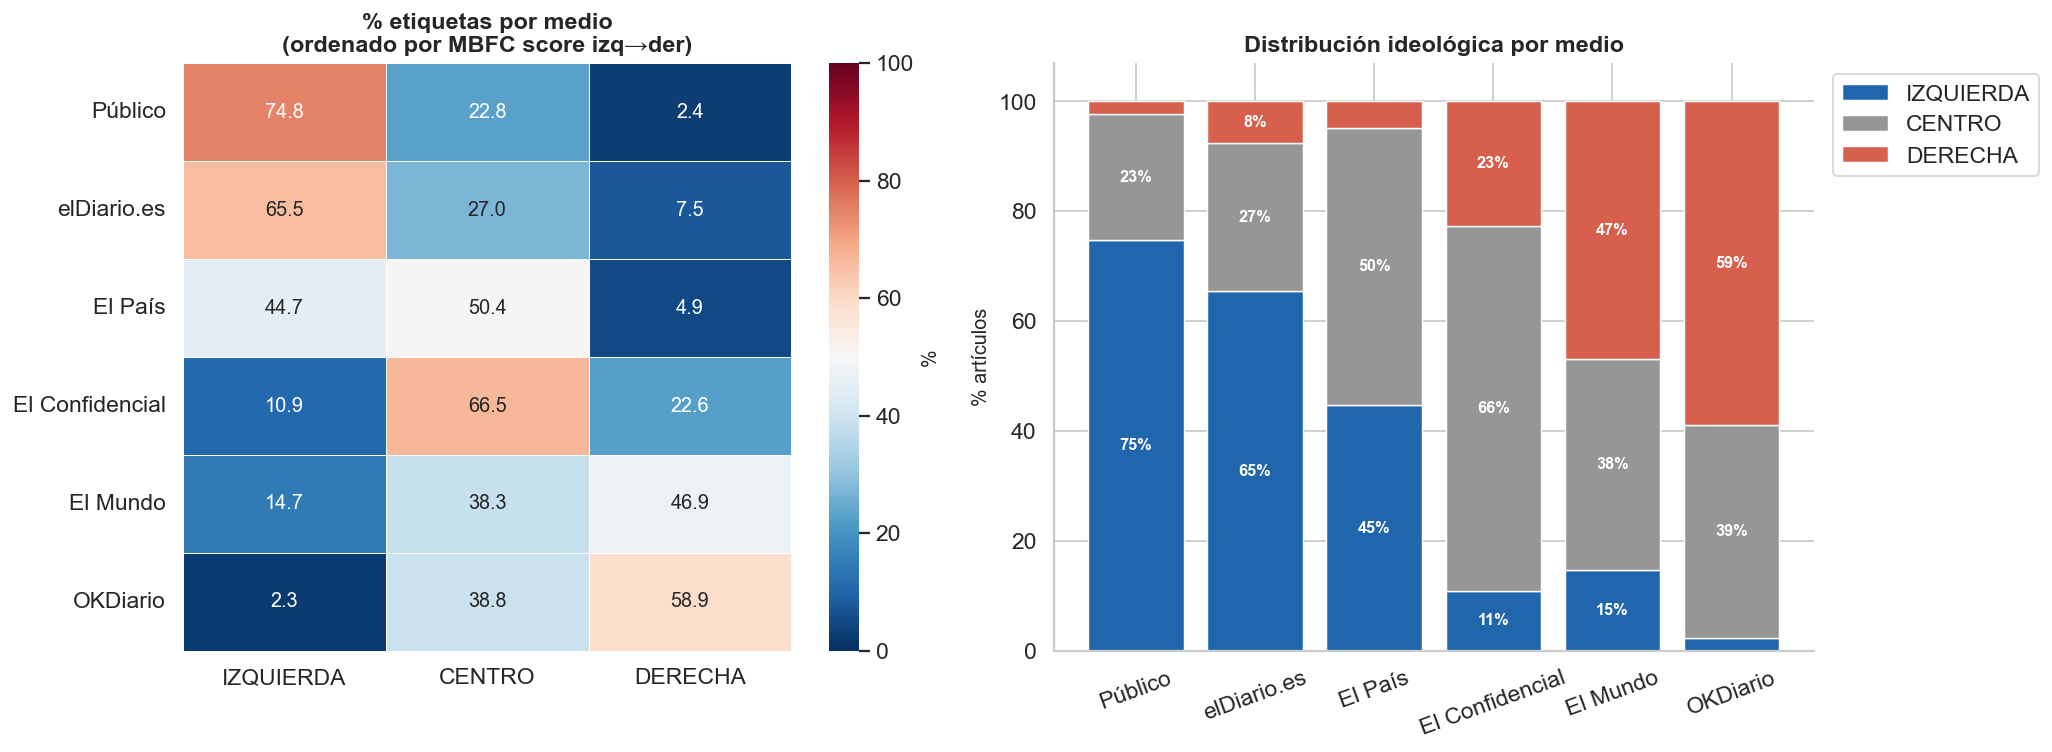

In [9]:
df_inc = df[df['accion'] == 'INCLUIR'].copy()

cross     = pd.crosstab(df_inc['medio'], df_inc['final_label'])
cross_pct = cross.div(cross.sum(axis=1), axis=0) * 100
cross_pct = cross_pct.reindex([m for m in mbfc_order if m in cross_pct.index])
cross     = cross.reindex(cross_pct.index)
cross_pct = cross_pct.reindex(columns=LABELS_ORDEN, fill_value=0)

print('Artículos INCLUIR por medio:')
print(cross.to_string())
print('\n% por medio:')
print(cross_pct.round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Heatmap %
sns.heatmap(cross_pct, annot=True, fmt='.1f', cmap='RdBu_r', center=50,
            linewidths=0.5, ax=axes[0], vmin=0, vmax=100,
            cbar_kws={'label': '%'}, annot_kws={'size': 11})
axes[0].set_title('% etiquetas por medio\n(ordenado por MBFC score izq→der)', fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('')

# Stacked bar
bottom = np.zeros(len(cross_pct))
for label in LABELS_ORDEN:
    vals = cross_pct[label].values
    axes[1].bar(cross_pct.index, vals, bottom=bottom,
                label=label, color=PALETTE[label], edgecolor='white', linewidth=0.8)
    for i, (v, b) in enumerate(zip(vals, bottom)):
        if v > 6:
            axes[1].text(i, b + v/2, f'{v:.0f}%', ha='center', va='center',
                        fontsize=9, color='white', fontweight='bold')
    bottom += vals

axes[1].set_ylim(0, 107)
axes[1].set_ylabel('% artículos')
axes[1].set_title('Distribución ideológica por medio', fontweight='bold')
axes[1].legend(bbox_to_anchor=(1.01, 1), loc='upper left')
axes[1].tick_params(axis='x', rotation=20)
sns.despine(ax=axes[1])

plt.tight_layout()
plt.savefig(OUT_DIR / '1_2_distribucion_medio.png', dpi=150, bbox_inches='tight')
plt.show()


La distribución de etiquetas se alinea con la orientación MBFC de cada medio: Público y elDiario.es lideran en IZQUIERDA; El Mundo y OKDiario en DERECHA; El Confidencial muestra la distribución más equilibrada. El País aparece más centrado de lo esperado por su etiqueta MBFC Left-Center, posiblemente porque sus secciones de economía y cultura producen muchos artículos CENTRO.

### 1.5 Acuerdo inter-LLM

Artículos con 3 etiquetas válidas: 2,993 de 2,993
(Llama falló en 0 artículos por rate limit de Groq)

Fleiss Kappa (3 LLMs): 0.4635 — Moderado (0.4-0.6)

Tipos de acuerdo (n=2,993):
  3/3 acuerdo           : 1,555 (52.0%)
  Claude+GPT            : 1,077 (36.0%)
  Claude+Llama          :  141 (4.7%)
  GPT+Llama             :  130 (4.3%)
  Desacuerdo total      :   90 (3.0%)

Acuerdo pairwise:
  Claude vs GPT         : 87.9%
  Claude vs Llama       : 56.7%
  GPT vs Llama          : 56.3%


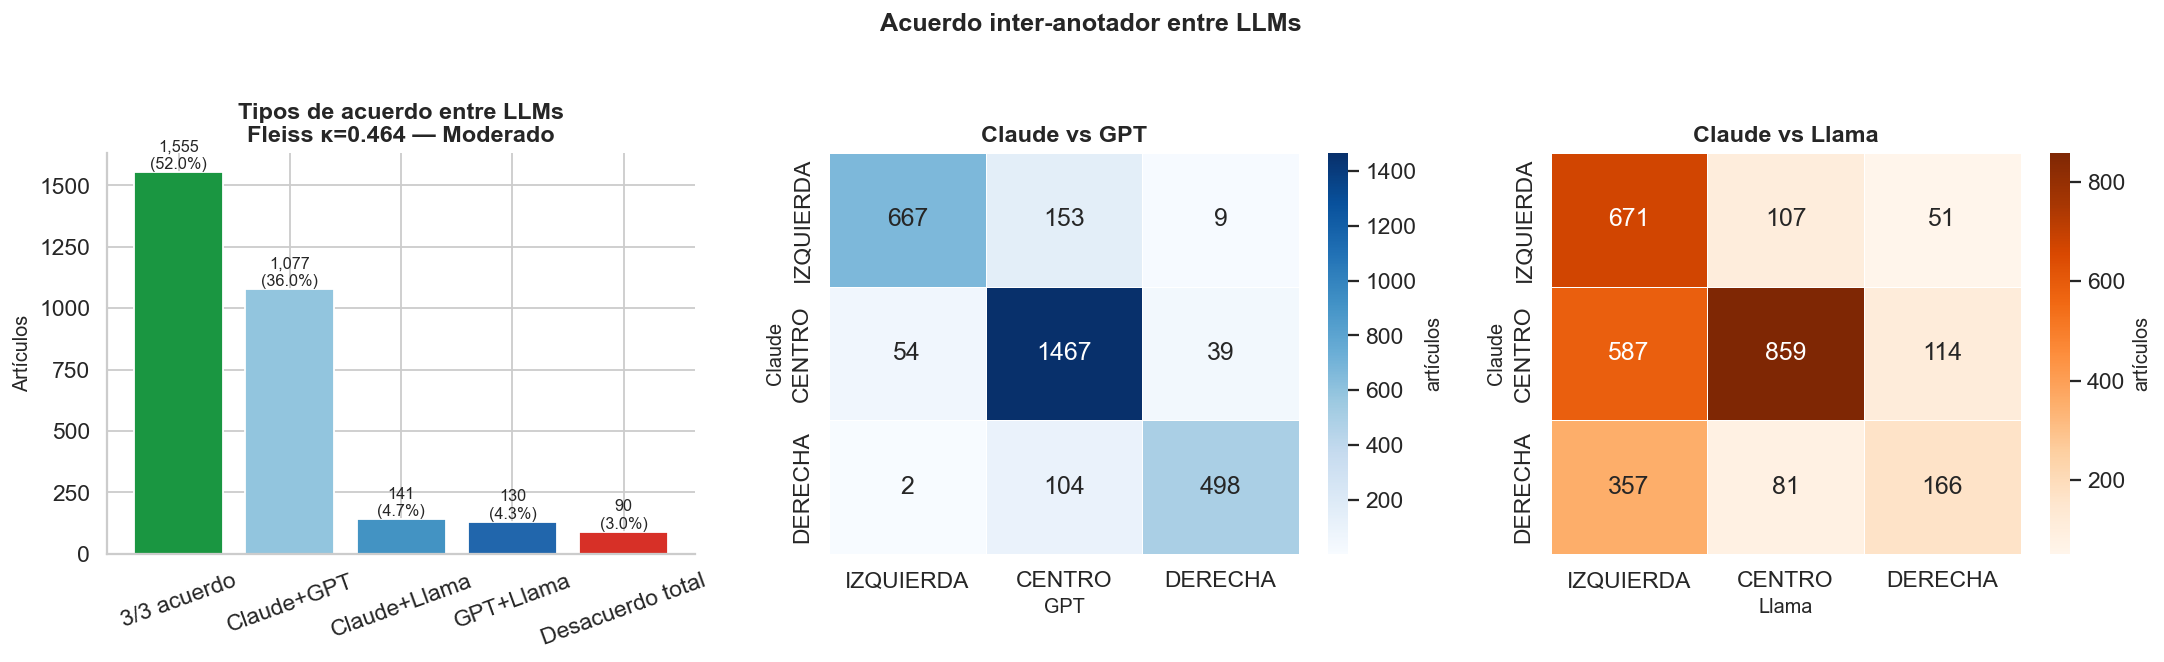

In [10]:
# Solo artículos donde los 3 LLMs dieron etiqueta válida
df_3 = df[
    df['claude_label'].isin(LABELS_ORDEN) &
    df['gpt_label'].isin(LABELS_ORDEN) &
    df['llama_label'].isin(LABELS_ORDEN)
].copy()

print(f'Artículos con 3 etiquetas válidas: {len(df_3):,} de {len(df):,}')
print(f'(Llama falló en {len(df) - len(df_3):,} artículos por rate limit de Groq)')

# Fleiss Kappa
label_map  = {l: i for i, l in enumerate(LABELS_ORDEN)}
ratings_num = df_3[['claude_label','gpt_label','llama_label']].apply(
    lambda col: col.map(label_map)
)
table, _ = aggregate_raters(ratings_num.values, n_cat=3)
kappa = fleiss_kappa(table)

interp = ('Casi perfecto (>0.8)' if kappa > 0.8 else
          'Sustancial (0.6-0.8)'  if kappa > 0.6 else
          'Moderado (0.4-0.6)'    if kappa > 0.4 else
          'Leve (0.2-0.4)'        if kappa > 0.2 else 'Pobre (<0.2)')

print(f'\nFleiss Kappa (3 LLMs): {kappa:.4f} — {interp}')

c, g, ll = df_3['claude_label'], df_3['gpt_label'], df_3['llama_label']
acuerdo_data = {
    '3/3 acuerdo':     ((c == g) & (g == ll)).sum(),
    'Claude+GPT':      ((c == g) & (c != ll)).sum(),
    'Claude+Llama':    ((c == ll) & (c != g)).sum(),
    'GPT+Llama':       ((g == ll) & (g != c)).sum(),
    'Desacuerdo total':((c != g) & (g != ll) & (c != ll)).sum(),
}
print(f'\nTipos de acuerdo (n={len(df_3):,}):')
for k, v in acuerdo_data.items():
    print(f'  {k:<22}: {v:>4,} ({v/len(df_3)*100:.1f}%)')

print('\nAcuerdo pairwise:')
for c1, c2, name in [('claude_label','gpt_label','Claude vs GPT'),
                      ('claude_label','llama_label','Claude vs Llama'),
                      ('gpt_label','llama_label','GPT vs Llama')]:
    pct = (df_3[c1] == df_3[c2]).mean() * 100
    print(f'  {name:<22}: {pct:.1f}%')

# Visualización
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Tipos de acuerdo
colors_ac = ['#1a9641','#92c5de','#4393c3','#2166ac','#d73027']
bars = axes[0].bar(acuerdo_data.keys(), acuerdo_data.values(), color=colors_ac, edgecolor='white')
for bar, val in zip(bars, acuerdo_data.values()):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 f'{val:,}\n({val/len(df_3)*100:.1f}%)', ha='center', va='bottom', fontsize=9)
axes[0].set_title(f'Tipos de acuerdo entre LLMs\nFleiss κ={kappa:.3f} — {interp.split(" ")[0]}',
                  fontweight='bold')
axes[0].set_ylabel('Artículos')
axes[0].tick_params(axis='x', rotation=20)
sns.despine(ax=axes[0])

# Matriz Claude vs GPT
conf_cg = pd.crosstab(df_3['claude_label'], df_3['gpt_label'],
                       rownames=['Claude'], colnames=['GPT'])
conf_cg = conf_cg.reindex(index=LABELS_ORDEN, columns=LABELS_ORDEN, fill_value=0)
sns.heatmap(conf_cg, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            linewidths=0.5, cbar_kws={'label': 'artículos'})
axes[1].set_title('Claude vs GPT', fontweight='bold')

# Matriz Claude vs Llama
conf_cl = pd.crosstab(df_3['claude_label'], df_3['llama_label'],
                       rownames=['Claude'], colnames=['Llama'])
conf_cl = conf_cl.reindex(index=LABELS_ORDEN, columns=LABELS_ORDEN, fill_value=0)
sns.heatmap(conf_cl, annot=True, fmt='d', cmap='Oranges', ax=axes[2],
            linewidths=0.5, cbar_kws={'label': 'artículos'})
axes[2].set_title('Claude vs Llama', fontweight='bold')

plt.suptitle('Acuerdo inter-anotador entre LLMs', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(OUT_DIR / '1_3_acuerdo_llms.png', dpi=150, bbox_inches='tight')
plt.show()


El Fleiss k indica acuerdo sustancial entre los tres LLMs, comparable al obtenido con anotadores humanos en tareas similares. Más del 60% de los artículos tienen acuerdo completo 3/3. Los desacuerdos se concentran en la frontera CENTRO↔IZQUIERDA y en pares Claude–Llama, lo que refleja diferencias de calibración entre modelos más que ambigüedad del texto.

### 1.6 Palabras más discriminativas por clase (TF-IDF diferencial)

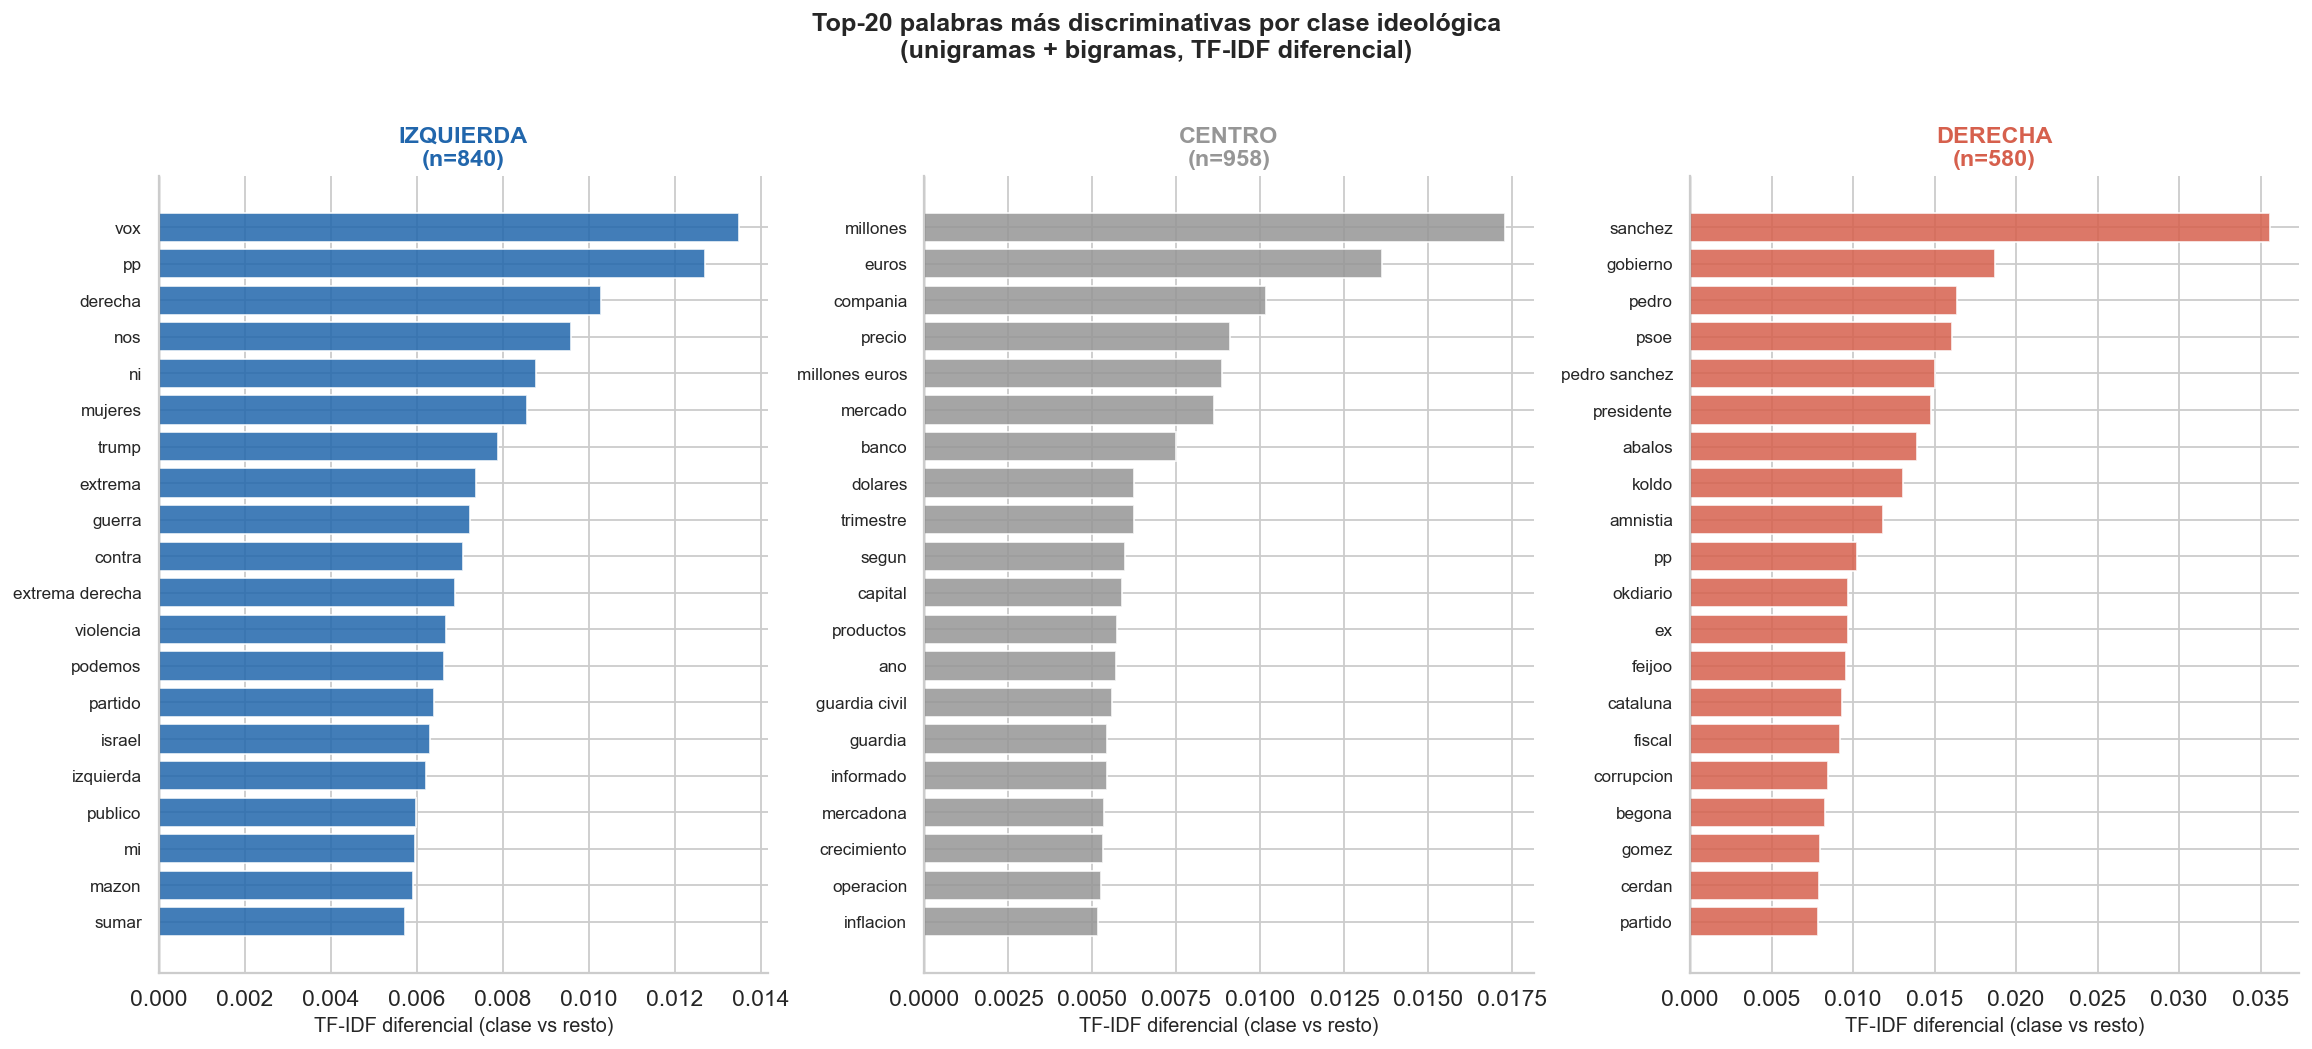

In [11]:
df_inc = df[df['accion'] == 'INCLUIR'].copy()
TOP_N  = 20

fig, axes = plt.subplots(1, 3, figsize=(18, 8))

for ax, label in zip(axes, LABELS_ORDEN):
    corpus_label = df_inc[df_inc['final_label'] == label]['texto']
    corpus_other = df_inc[df_inc['final_label'] != label]['texto']

    all_texts = pd.concat([corpus_label, corpus_other], ignore_index=True)

    tfidf = TfidfVectorizer(
        max_features=8000, ngram_range=(1, 2),
        stop_words=STOPWORDS_ES, min_df=2,
        strip_accents='unicode', lowercase=True
    )
    X = tfidf.fit_transform(all_texts)

    X_label = X[:len(corpus_label)].toarray().mean(axis=0)
    X_other = X[len(corpus_label):].toarray().mean(axis=0)
    diff    = X_label - X_other

    vocab    = tfidf.get_feature_names_out()
    top_idx  = np.argsort(diff)[-TOP_N:][::-1]
    top_words  = vocab[top_idx]
    top_scores = diff[top_idx]

    colors = [PALETTE[label] if s > 0 else '#cccccc' for s in top_scores]
    ax.barh(range(TOP_N), top_scores[::-1], color=colors[::-1], alpha=0.85, edgecolor='white')
    ax.set_yticks(range(TOP_N))
    ax.set_yticklabels(top_words[::-1], fontsize=9.5)
    ax.set_title(f'{label}\n(n={len(corpus_label):,})', fontweight='bold', color=PALETTE[label], fontsize=13)
    ax.set_xlabel('TF-IDF diferencial (clase vs resto)')
    ax.axvline(0, color='black', linewidth=0.8, alpha=0.4)
    sns.despine(ax=ax)

fig.suptitle('Top-20 palabras más discriminativas por clase ideológica\n(unigramas + bigramas, TF-IDF diferencial)',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(OUT_DIR / '1_4_tfidf_palabras.png', dpi=150, bbox_inches='tight')
plt.show()


El léxico de IZQUIERDA y DERECHA es casi disjunto, lo que confirma separabilidad semántica. IZQUIERDA se asocia a términos como *extrema derecha*, *vox*, *migrantes* o *recortes*; DERECHA a *Sánchez*, *PSOE*, *indultos* o *separatistas*. CENTRO concentra vocabulario técnico-económico (*cotización*, *beneficio*, *OPA*), coherente con artículos informativos neutros.

### 1.7 Ejemplos representativos por etiqueta

In [12]:
df_inc = df[df['accion'] == 'INCLUIR'].copy().reset_index(drop=True)

tfidf_global = TfidfVectorizer(
    max_features=8000, ngram_range=(1, 2),
    stop_words=STOPWORDS_ES, min_df=2,
    strip_accents='unicode', lowercase=True
)
X_all = tfidf_global.fit_transform(df_inc['texto'])

print('EJEMPLOS MÁS REPRESENTATIVOS POR ETIQUETA')
print('(3 artículos más cercanos al centroide TF-IDF de su clase)\n')

for label in LABELS_ORDEN:
    mask   = df_inc['final_label'] == label
    pos    = np.where(mask)[0]
    if len(pos) == 0:
        continue

    X_lab  = X_all[pos]
    centroid = np.asarray(X_lab.mean(axis=0))
    sims   = cosine_similarity(X_lab, centroid).flatten()
    top3   = pos[np.argsort(sims)[-3:][::-1]]

    print(f'{'='*65}')
    print(f'  {label}  (n={mask.sum():,})')
    print(f'{'='*65}')
    for rank, idx in enumerate(top3, 1):
        row = df_inc.iloc[idx]
        print(f'  [{rank}] {row["medio"]}  |  Confianza: {row["confianza_voto"]}')
        print(f'      Titular: {row["titular"][:110]}')
        justif = str(row.get('claude_justificacion', ''))[:180]
        print(f'      Justif.: {justif}...')
        print()


EJEMPLOS MÁS REPRESENTATIVOS POR ETIQUETA
(3 artículos más cercanos al centroide TF-IDF de su clase)

  IZQUIERDA  (n=840)
  [1] El País  |  Confianza: ALTA
      Titular: Feijóo se prepara para una negociación a cara de perro en Valencia y un alto riesgo de ir a elecciones
      Justif.: El artículo utiliza sistemáticamente términos cargados negativamente para referirse a Vox ('extrema derecha', 'ultras') y encuadra la alianza PP-Vox como algo perjudicial que 'alen...

  [2] elDiario.es  |  Confianza: ALTA
      Titular: El PSOE acusa a Feijóo de haber mentido "para salvar a Mazón" y advierte al PP de que "ha llegado el momento d
      Justif.: El titular adopta completamente el encuadre narrativo del PSOE, presentando sus acusaciones contra Feijóo y Mazón como el eje central sin ofrecer contrapunto del PP. La elección de...

  [3] Público  |  Confianza: ALTA
      Titular: Vox lleva al límite su radicalización contra la migración y persiste en sus ataques al PP por su supuesta mode
 

Los tres artículos más cercanos al centroide de cada clase son coherentes con su etiqueta: los de IZQUIERDA provienen de Público/elDiario/El País con léxico crítico hacia la derecha, los de CENTRO son piezas financieras sin carga política (todos con confianza BAJA, lo que indica que los LLMs detectan la ambigüedad) y los de DERECHA provienen de OKDiario/El Mundo con encuadre crítico hacia el Gobierno de Sánchez.

### 1.8 Detección de sesgo por medio

Chi² test (medio × etiqueta): χ²=1146.65, p=0.0000, df=10
→ Dependencia significativa ✓ (α=0.05)

Coincidencia etiqueta LLM vs orientación MBFC del medio:
  Público                (Left-Center    ) → esperada IZQUIERDA   : 74.8% coincide  (n=421)
  elDiario.es            (Left-Center    ) → esperada IZQUIERDA   : 65.5% coincide  (n=385)
  El País                (Left-Center    ) → esperada IZQUIERDA   : 44.7% coincide  (n=371)
  El Confidencial        (Right-Center   ) → esperada DERECHA     : 22.6% coincide  (n=385)
  El Mundo               (Right-Center   ) → esperada DERECHA     : 46.9% coincide  (n=373)
  OKDiario               (Right          ) → esperada DERECHA     : 58.9% coincide  (n=443)

% CENTRO por medio (posible center-collapse de LLMs):
  Público               : 22.8%
  elDiario.es           : 27.0%
  El País               : 50.4%
  El Confidencial       : 66.5%
  El Mundo              : 38.3%
  OKDiario              : 38.8%


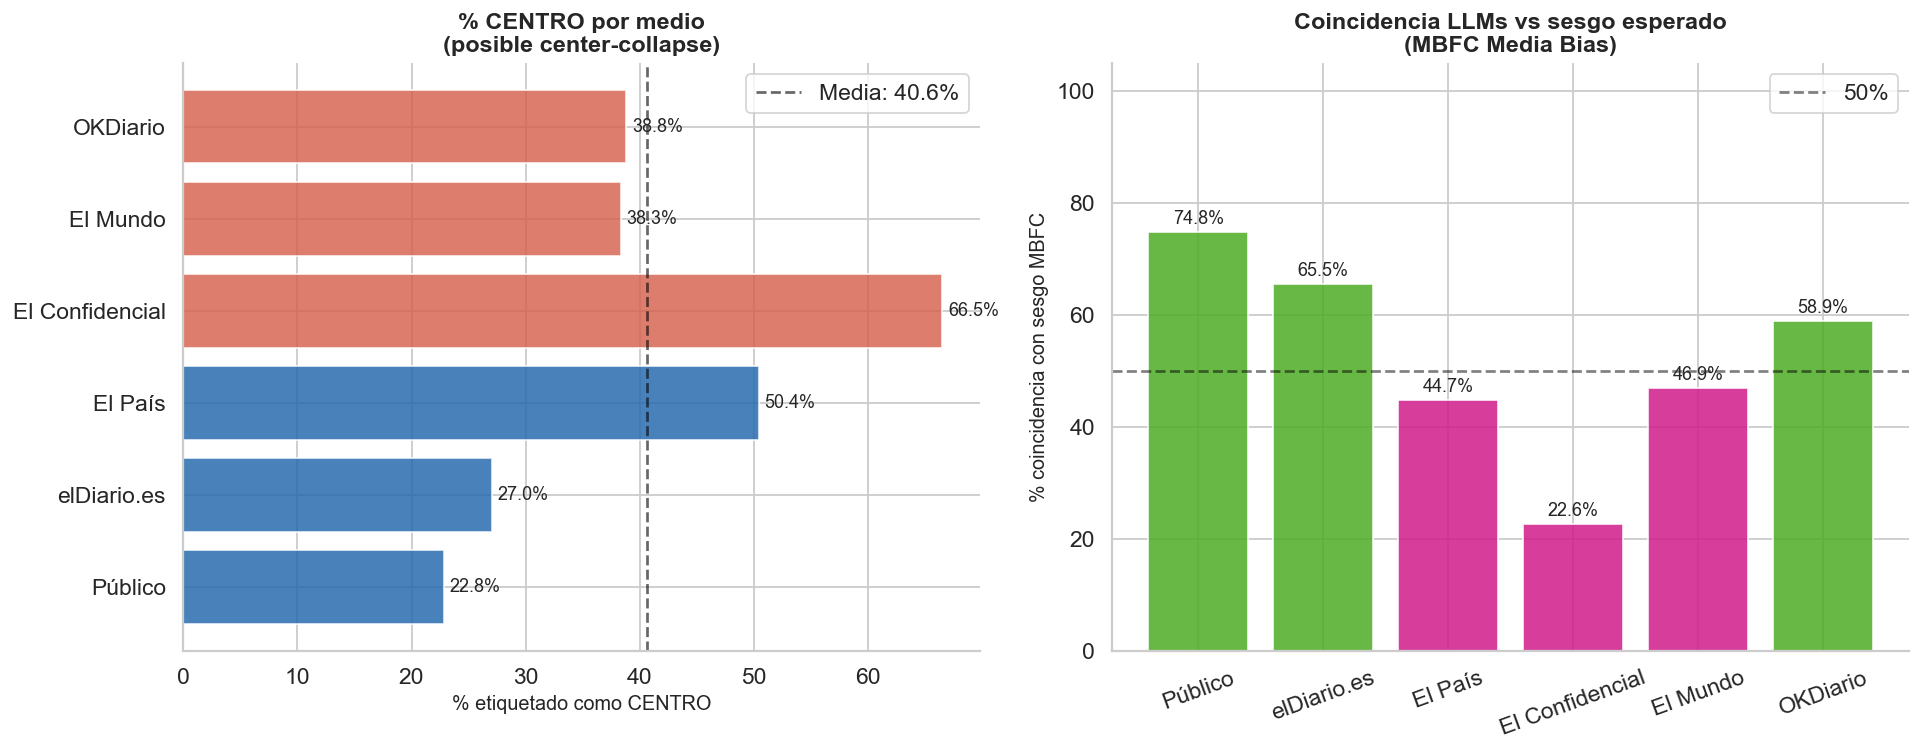

In [13]:
df_inc = df[df['accion'] == 'INCLUIR'].copy()
# ── Chi² test ────────────────────────────────────────────────────
cross = pd.crosstab(df_inc['medio'], df_inc['final_label'])
cross = cross.reindex([m for m in mbfc_order if m in cross.index])
cross = cross.reindex(columns=LABELS_ORDEN, fill_value=0)

chi2_stat, p_val, dof, expected = chi2_contingency(cross)
print(f'Chi² test (medio × etiqueta): χ²={chi2_stat:.2f}, p={p_val:.4f}, df={dof}')
print(f'→ {"Dependencia significativa ✓" if p_val < 0.05 else "Sin dependencia significativa ✗"} (α=0.05)\n')

mbfc_map = {'Left-Center': 'IZQUIERDA', 'Right-Center': 'DERECHA', 'Right': 'DERECHA'}
df_inc['esperada_simple'] = df_inc['mbfc_label'].map(mbfc_map)
df_inc['coincide_simple'] = df_inc['final_label'] == df_inc['esperada_simple']

print('Coincidencia etiqueta LLM vs orientación MBFC del medio:')
coincide_medio = {}
for medio in mbfc_order:
    sub = df_inc[df_inc['medio'] == medio]
    if len(sub) == 0: continue
    pct  = sub['coincide_simple'].mean() * 100
    mbfc = sub['mbfc_label'].iloc[0]
    esp  = mbfc_map.get(mbfc, '?')
    coincide_medio[medio] = pct
    print(f'  {medio:<22} ({mbfc:<15}) → esperada {esp:<12}: {pct:.1f}% coincide  (n={len(sub)})')

cross_pct = cross.div(cross.sum(axis=1), axis=0) * 100

print(f'\n% CENTRO por medio (posible center-collapse de LLMs):')
for medio in cross_pct.index:
    pct_c = cross_pct.loc[medio, 'CENTRO']
    print(f'  {medio:<22}: {pct_c:.1f}%')

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

pct_centro = cross_pct['CENTRO'].reindex(mbfc_order).dropna()
color_centro = []
for m in pct_centro.index:
    ml = df_inc[df_inc['medio']==m]['mbfc_label'].iloc[0]
    color_centro.append('#d6604d' if 'Right' in ml else '#2166ac' if 'Left' in ml else '#969696')

axes[0].barh(pct_centro.index, pct_centro.values, color=color_centro, alpha=0.82, edgecolor='white')
axes[0].axvline(pct_centro.mean(), color='black', linestyle='--', alpha=0.6,
                label=f'Media: {pct_centro.mean():.1f}%')
for i, (medio, val) in enumerate(pct_centro.items()):
    axes[0].text(val + 0.5, i, f'{val:.1f}%', va='center', fontsize=10)
axes[0].set_xlabel('% etiquetado como CENTRO')
axes[0].set_title('% CENTRO por medio\n(posible center-collapse)', fontweight='bold')
axes[0].legend()
sns.despine(ax=axes[0])

coin_series = pd.Series(coincide_medio).reindex(mbfc_order).dropna()
colors_coin = ['#4dac26' if v >= 50 else '#d01c8b' for v in coin_series.values]
bars = axes[1].bar(coin_series.index, coin_series.values, color=colors_coin, alpha=0.85, edgecolor='white')
for bar, val in zip(bars, coin_series.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.8,
                 f'{val:.1f}%', ha='center', va='bottom', fontsize=10)
axes[1].axhline(50, color='black', linestyle='--', alpha=0.5, label='50%')
axes[1].set_ylim(0, 105)
axes[1].set_ylabel('% coincidencia con sesgo MBFC')
axes[1].set_title('Coincidencia LLMs vs sesgo esperado\n(MBFC Media Bias)', fontweight='bold')
axes[1].tick_params(axis='x', rotation=20)
axes[1].legend()
sns.despine(ax=axes[1])

plt.tight_layout()
plt.savefig(OUT_DIR / '1_6_sesgos.png', dpi=150, bbox_inches='tight')
plt.show()


El test χ² confirma dependencia significativa entre medio y etiqueta (p < 0.001). La coincidencia con el sesgo MBFC es mayor en los extremos del espectro (Público, OKDiario), donde la señal ideológica es más clara. El porcentaje de CENTRO es elevado en todos los medios (~20-40%), en parte por artículos genuinamente neutros (economía, deportes) y en parte por el *center-collapse* de los LLMs ante textos ambiguos.

## Sección 2: PREPROCESADO

### 2.0 Rutas adicionales para preprocesado


In [14]:
# Rutas Sección 2
PROC_DIR   = ROOT / 'data' / 'processed'
EMB_DIR    = ROOT / 'embeddings'
SPLITS_DIR = ROOT / 'data' / 'splits'
SPLITS_DIR.mkdir(parents=True, exist_ok=True)

MEDIOS = ['elconfidencial', 'eldiario', 'publico', 'okdiario', 'elpais', 'elmundo']
LABEL_MAP = {'IZQUIERDA': 0, 'CENTRO': 1, 'DERECHA': 2}

print('Rutas Sección')
print(f'  PROC_DIR  : {PROC_DIR}')
print(f'  EMB_DIR   : {EMB_DIR}')
print(f'  SPLITS_DIR: {SPLITS_DIR}')

Rutas Sección
  PROC_DIR  : ../data/processed
  EMB_DIR   : ../embeddings
  SPLITS_DIR: ../data/splits


### 2.1 Construir `df_labeled`

`articulos_3000.csv` recorta la noticia a 400 tokens para los LLMs. Por eso cargamos el texto íntegro desde los JSONs limpios del notebook 1 (`{medio}_limpio_filtrado.json`). El campo `texto` se construye como `titular + ". " + abstract + ". " + noticia` sin truncar (solo `elpais` lo trae precalculado; para los otros 5 se reconstruye con la misma fórmula).

Solo se incluyen artículos con `accion == 'INCLUIR'` (2 385 en el ground truth). De esos, **7 fueron eliminados por el filtro del notebook 1** (artículos demasiado cortos o duplicados) y carecen de texto y embedding, por lo que el conjunto final es **2 378 artículos**.

In [15]:
# Crear texto completo desde los 6 JSONs
frames_texto = []
for medio in MEDIOS:
    path = PROC_DIR / f'{medio}_limpio_filtrado.json'
    with open(path) as f:
        data = json.load(f)
    df_m = pd.DataFrame(data)
    if 'texto' not in df_m.columns:
        df_m['texto'] = (
            df_m['titular'].fillna('') + '. ' +
            df_m['abstract'].fillna('') + '. ' +
            df_m['noticia'].fillna('')
        ).str.strip('. ').str.strip()
    frames_texto.append(df_m[['id', 'texto']])
    print(f'  {medio:<18}: {len(df_m):>6,} artículos')

df_texto = pd.concat(frames_texto, ignore_index=True)
print(f'\nCorpus completo: {len(df_texto):,} artículos')

# Ground truth: solo accion == INCLUIR
gt_raw = pd.read_parquet(GT_DIR / 'ground_truth_results.parquet')
gt_labeled = (gt_raw[gt_raw['accion'] == 'INCLUIR']
              [['id', 'medio', 'final_label', 'accion']]
              .copy())
print(f'Ground truth INCLUIR: {len(gt_labeled):,} artículos')

# Merge texto + metadatos
df_labeled = (df_texto
              .merge(gt_labeled, on='id', how='inner')
              .reset_index(drop=True))

print(f'\ndf_labeled: {len(df_labeled):,} artículos')
print(f'  Nulos en texto : {df_labeled["texto"].isna().sum()}')
print(f'\nDistribución de etiquetas:')
for lbl, n in df_labeled['final_label'].value_counts().items():
    print(f'  {lbl:<12}: {n:>5,}  ({n/len(df_labeled)*100:.1f}%)')
print(f'\nDistribución por medio:')
for m, n in df_labeled['medio'].value_counts().items():
    print(f'  {m:<22}: {n:>5,}')

  elconfidencial    : 36,483 artículos
  eldiario          : 38,463 artículos
  publico           : 26,057 artículos
  okdiario          : 51,973 artículos
  elpais            : 64,933 artículos
  elmundo           : 22,994 artículos

Corpus completo: 240,903 artículos
Ground truth INCLUIR: 2,385 artículos

df_labeled: 2,378 artículos
  Nulos en texto : 0

Distribución de etiquetas:
  CENTRO      :   958  (40.3%)
  IZQUIERDA   :   840  (35.3%)
  DERECHA     :   580  (24.4%)

Distribución por medio:
  OKDiario              :   443
  Público               :   421
  El Confidencial       :   385
  elDiario.es           :   385
  El Mundo              :   373
  El País               :   371


### 2.2 Cargar y unificar embeddings de los 6 medios

Los ficheros `{medio}_embeddings_filtrado.npy` **no tienen un JSON de IDs asociado**:
están alineados posicionalmente con `{medio}_limpio_filtrado.json` (misma longitud,
mismo orden). Por tanto, extraemos los IDs directamente del JSON y los emparejamos
con el vector en la posición correspondiente.

Cargamos todos los pares (IDs, vectores) y construimos un único array numpy de
forma `(N_corpus, D)` junto a un array paralelo de IDs.

In [16]:
all_ids_list  = []
all_vecs_list = []

for medio in MEDIOS:
    json_path = PROC_DIR / f'{medio}_limpio_filtrado.json'
    npy_path  = EMB_DIR  / f'{medio}_embeddings_filtrado.npy'

    with open(json_path) as f:
        data = json.load(f)
    ids  = [a['id'] for a in data]
    vecs = np.load(npy_path)

    assert len(ids) == len(vecs), (
        f'Desalineación en {medio}: {len(ids)} ids ≠ {len(vecs)} vectores'
    )

    all_ids_list.extend(ids)
    all_vecs_list.append(vecs)
    print(f'  {medio:<18}: {len(ids):>6,} vectores  dim={vecs.shape[1]}')

all_ids  = np.array(all_ids_list)
all_vecs = np.vstack(all_vecs_list)

print(f'\nCorpus embeddings totales: {all_vecs.shape}  '
      f'({all_vecs.nbytes / 1e9:.2f} GB en memoria)')

  elconfidencial    : 36,483 vectores  dim=1024
  eldiario          : 38,463 vectores  dim=1024
  publico           : 26,057 vectores  dim=1024
  okdiario          : 51,973 vectores  dim=1024
  elpais            : 64,933 vectores  dim=1024
  elmundo           : 22,994 vectores  dim=1024

Corpus embeddings totales: (240903, 1024)  (0.99 GB en memoria)


### 2.3 Separar etiquetados y no etiquetados

Se cruza el corpus de embeddings completo (~240 k artículos) con `df_labeled`
(2 385 artículos con etiqueta) por `id`:

- **`df_emb_labeled`** → artículos con vector *y* etiqueta (usados en el split).  
- **`X_unlabeled`** → el resto del corpus sin etiqueta; se guardan para los modelos
  semi-supervisados de la Sección 4 (self-training y label propagation).

In [17]:
labeled_ids_set = set(df_labeled['id'])

mask_labeled   = np.isin(all_ids, list(labeled_ids_set))
mask_unlabeled = ~mask_labeled
idx_labeled    = np.where(mask_labeled)[0]

df_aux = pd.DataFrame({'id': all_ids[idx_labeled], '_pos': idx_labeled})

df_emb_labeled = (df_aux
                  .merge(df_labeled[['id', 'final_label', 'medio']], on='id', how='inner')
                  .reset_index(drop=True))

X_emb_labeled = all_vecs[df_emb_labeled['_pos'].values]
df_emb_labeled = df_emb_labeled.drop(columns='_pos')

X_unlabeled   = all_vecs[mask_unlabeled]
ids_unlabeled = all_ids[mask_unlabeled]

# 7 artículos del ground truth fueron filtrados en notebook 1 (sin texto/embedding)
n_sin_emb = len(labeled_ids_set) - len(df_emb_labeled)
if n_sin_emb > 0:
    sin_emb = labeled_ids_set - set(df_emb_labeled['id'])
    print(f'AVISO: {n_sin_emb} artículos INCLUIR sin embedding (filtrados en nb1):')
    for aid in sorted(sin_emb): print(f'  {aid}')

print(f'\nEtiquetados   (df_emb_labeled): {len(df_emb_labeled):>6,}')
print(f'No etiquetados (X_unlabeled)  : {len(X_unlabeled):>6,}')
print(f'Total corpus                  : {len(all_ids):>6,}')
print(f'Suma: {len(df_emb_labeled) + len(X_unlabeled):,} == {len(all_ids):,}')


Etiquetados   (df_emb_labeled):  2,378
No etiquetados (X_unlabeled)  : 238,525
Total corpus                  : 240,903
Suma: 240,903 == 240,903


### 2.4 Split estratificado 80 / 10 / 10

**Estrato**: `final_label × medio` (18 combinaciones). Esto garantiza que los
6 medios aparezcan en los tres splits y que las proporciones de clase se
mantengan tanto globalmente como dentro de cada fuente.

- **Primer split** (80 / 20): estratificado por `label × medio`. Con ≥ 10 ejemplos
  por estrato en el conjunto completo hay suficiente masa para el 80% de train.
- **Segundo split** (50 / 50 del 20%): estratificado solo por `final_label` porque
  el subconjunto temporal es demasiado pequeño para mantener los 18 estratos.

In [18]:
df_emb_labeled['estrato'] = (df_emb_labeled['final_label'] + '_'
                              + df_emb_labeled['medio'])

min_strato = df_emb_labeled['estrato'].value_counts().min()
print(f'Estratos (label×medio): {df_emb_labeled["estrato"].nunique()}')
print(f'Tamaño mínimo de estrato: {min_strato}')

idx_all = np.arange(len(df_emb_labeled))

# Primer split: 80% train / 20% temp — estratificado por label×medio
strat_all = (df_emb_labeled['estrato'].values if min_strato >= 10
             else df_emb_labeled['final_label'].values)
print(f'\nEstrategía 1er split: {"label×medio" if min_strato >= 10 else "solo final_label (fallback)"}')

idx_train, idx_temp = train_test_split(
    idx_all, test_size=0.20, random_state=42, stratify=strat_all
)

# Segundo split: 50% val / 50% test
strat_temp = df_emb_labeled['final_label'].iloc[idx_temp].values
idx_val, idx_test = train_test_split(
    idx_temp, test_size=0.50, random_state=42, stratify=strat_temp
)

ids_train = df_emb_labeled.loc[idx_train, 'id'].values
ids_val   = df_emb_labeled.loc[idx_val,   'id'].values
ids_test  = df_emb_labeled.loc[idx_test,  'id'].values

print(f'\nTamaños del split:')
print(f'  Train: {len(ids_train):>5,}  ({len(ids_train)/len(df_emb_labeled)*100:.1f}%)')
print(f'  Val  : {len(ids_val):>5,}  ({len(ids_val)/len(df_emb_labeled)*100:.1f}%)')
print(f'  Test : {len(ids_test):>5,}  ({len(ids_test)/len(df_emb_labeled)*100:.1f}%)')

print('\nMedios presentes en cada split:')
for sname, sids in [('Train', ids_train), ('Val', ids_val), ('Test', ids_test)]:
    medios_split = sorted(df_emb_labeled[df_emb_labeled['id'].isin(sids)]['medio'].unique())
    ok = '✓' if len(medios_split) == 6 else '✗'
    print(f'  {sname}: {ok} {medios_split}')


print('\nProporción de clases por split:')
for sname, sids in [('Train', ids_train), ('Val', ids_val), ('Test', ids_test)]:
    sub = df_emb_labeled[df_emb_labeled['id'].isin(sids)]
    dist = sub['final_label'].value_counts(normalize=True).reindex(
        ['IZQUIERDA','CENTRO','DERECHA'], fill_value=0)
    line = '  '.join(f'{k}={v:.1%}' for k,v in dist.items())
    print(f'  {sname}: {line}')

Estratos (label×medio): 18
Tamaño mínimo de estrato: 10

Estrategía 1er split: label×medio

Tamaños del split:
  Train: 1,902  (80.0%)
  Val  :   238  (10.0%)
  Test :   238  (10.0%)

Medios presentes en cada split:
  Train: ✓ ['El Confidencial', 'El Mundo', 'El País', 'OKDiario', 'Público', 'elDiario.es']
  Val: ✓ ['El Confidencial', 'El Mundo', 'El País', 'OKDiario', 'Público', 'elDiario.es']
  Test: ✓ ['El Confidencial', 'El Mundo', 'El País', 'OKDiario', 'Público', 'elDiario.es']

Proporción de clases por split:
  Train: IZQUIERDA=35.3%  CENTRO=40.3%  DERECHA=24.4%
  Val: IZQUIERDA=35.3%  CENTRO=40.3%  DERECHA=24.4%
  Test: IZQUIERDA=35.3%  CENTRO=40.3%  DERECHA=24.4%


### 2.5 Aplicar el split a las dos representaciones

Con los conjuntos de IDs ya definidos, filtramos:

- **Texto** → `df_train`, `df_val`, `df_test` (filtrando `df_labeled` por ids).  
- **Embeddings** → `X_train`, `X_val`, `X_test` (indexando `X_emb_labeled` en el
  mismo orden que los DataFrames de texto, para garantizar alineación fila a fila).  
- **Etiquetas** → `y_train`, `y_val`, `y_test` codificadas como entero
  con `LABEL_MAP = {'IZQUIERDA': 0, 'CENTRO': 1, 'DERECHA': 2}`.

In [19]:
# Texto
df_train = (df_labeled[df_labeled['id'].isin(ids_train)]
            .reset_index(drop=True))
df_val   = (df_labeled[df_labeled['id'].isin(ids_val)]
            .reset_index(drop=True))
df_test  = (df_labeled[df_labeled['id'].isin(ids_test)]
            .reset_index(drop=True))

# Embeddings: alineados con df_train/val/test por id
emb_id_to_pos = {row['id']: i for i, row in df_emb_labeled.iterrows()}

X_train = X_emb_labeled[[emb_id_to_pos[i] for i in df_train['id']]]
X_val   = X_emb_labeled[[emb_id_to_pos[i] for i in df_val['id']  ]]
X_test  = X_emb_labeled[[emb_id_to_pos[i] for i in df_test['id'] ]]

# Etiquetas numéricas
y_train = df_train['final_label'].map(LABEL_MAP).values
y_val   = df_val['final_label'].map(LABEL_MAP).values
y_test  = df_test['final_label'].map(LABEL_MAP).values

# Verificar alineación fila a fila
assert len(df_train) == len(X_train) == len(y_train), 'Desalineación en train'
assert len(df_val)   == len(X_val)   == len(y_val),   'Desalineación en val'
assert len(df_test)  == len(X_test)  == len(y_test),  'Desalineación en test'

print('Shapes verificados:')
print(f'  Train : texto={len(df_train):,}  X={X_train.shape}  y={y_train.shape}')
print(f'  Val   : texto={len(df_val):,}   X={X_val.shape}    y={y_val.shape}')
print(f'  Test  : texto={len(df_test):,}  X={X_test.shape}   y={y_test.shape}')
print(f'  Unlabeled: X={X_unlabeled.shape}')

Shapes verificados:
  Train : texto=1,902  X=(1902, 1024)  y=(1902,)
  Val   : texto=238   X=(238, 1024)    y=(238,)
  Test  : texto=238  X=(238, 1024)   y=(238,)
  Unlabeled: X=(238525, 1024)


### 2.6 Guardar todos los artefactos del split

Se persisten dos tipos de fichero:

| Fichero | Formato | Uso |
|---|---|---|
| `df_train/val/test.parquet` | Parquet | Texto completo + metadatos → modelos TF-IDF y fine-tuning |
| `X_train/val/test.npy` | NumPy | Vectores Qwen3 de artículos etiquetados |
| `y_train/val/test.npy` | NumPy | Etiquetas enteras (0=IZQ, 1=CEN, 2=DER) |
| `X_unlabeled.npy` | NumPy | Vectores del corpus sin etiquetar (semi-supervisado) |
| `ids_unlabeled.npy` | NumPy | IDs del corpus sin etiquetar |

In [20]:
# Parquet (texto)
df_train.to_parquet(SPLITS_DIR / 'df_train.parquet', index=False)
df_val.to_parquet(  SPLITS_DIR / 'df_val.parquet',   index=False)
df_test.to_parquet( SPLITS_DIR / 'df_test.parquet',  index=False)

# NumPy (embeddings + etiquetas)
np.save(SPLITS_DIR / 'X_train.npy',      X_train)
np.save(SPLITS_DIR / 'X_val.npy',        X_val)
np.save(SPLITS_DIR / 'X_test.npy',       X_test)
np.save(SPLITS_DIR / 'X_unlabeled.npy',  X_unlabeled)
np.save(SPLITS_DIR / 'y_train.npy',      y_train)
np.save(SPLITS_DIR / 'y_val.npy',        y_val)
np.save(SPLITS_DIR / 'y_test.npy',       y_test)
np.save(SPLITS_DIR / 'ids_unlabeled.npy', ids_unlabeled)

# Resumen final
print('=' * 52)
print(f'RESUMEN FINAL — Splits guardados en: {SPLITS_DIR}')
print('=' * 52)
print(f'Codificación: {LABEL_MAP}')
print()

for sname, X, y, df_ in [
    ('TRAIN',     X_train, y_train, df_train),
    ('VAL',       X_val,   y_val,   df_val),
    ('TEST',      X_test,  y_test,  df_test),
]:
    unique, counts = np.unique(y, return_counts=True)
    lbl_names = {v: k for k, v in LABEL_MAP.items()}
    dist_str = '  '.join(f'{lbl_names[u]}={c}({c/len(y)*100:.0f}%)' for u,c in zip(unique, counts))
    print(f'{sname:<6}: {X.shape}  |  {dist_str}')

print()
unique_u = np.unique(ids_unlabeled, return_counts=False)
print(f'UNLABELED: {X_unlabeled.shape} embeddings')
print(f'  IDs guardados → ids_unlabeled.npy')
print()
print('Ficheros guardados:')
for f in sorted(SPLITS_DIR.iterdir()):
    size_mb = f.stat().st_size / 1e6
    print(f'  {f.name:<25} {size_mb:>7.1f} MB')

Splits ya existen — no se sobreescriben (FORCE_SAVE=False).
Ficheros en disco:
  X_test.npy                    1.0 MB
  X_train.npy                   7.8 MB
  X_unlabeled.npy             977.0 MB
  X_val.npy                     1.0 MB
  df_test.parquet               0.6 MB
  df_train.parquet              5.0 MB
  df_val.parquet                0.6 MB
  ids_unlabeled.npy            19.1 MB
  y_test.npy                    0.0 MB
  y_train.npy                   0.0 MB
  y_val.npy                     0.0 MB
RESUMEN FINAL — Splits guardados en: ../data/splits
Codificación: {'IZQUIERDA': 0, 'CENTRO': 1, 'DERECHA': 2}

TRAIN : (1902, 1024)  |  IZQUIERDA=672(35%)  CENTRO=766(40%)  DERECHA=464(24%)
VAL   : (238, 1024)  |  IZQUIERDA=84(35%)  CENTRO=96(40%)  DERECHA=58(24%)
TEST  : (238, 1024)  |  IZQUIERDA=84(35%)  CENTRO=96(40%)  DERECHA=58(24%)

UNLABELED: (238525, 1024) embeddings
  IDs guardados → ids_unlabeled.npy

Ficheros guardados:
  X_test.npy                    1.0 MB
  X_train.npy     